# 10 · Error analysis: where the best model fails, and why (task T26, RQ4)

A results table says how well a model does. This notebook asks where it goes wrong and why, on the test chips and on the held-out Bolivia flood.

1. Take the best U-Net, chosen by **validation** IoU (never by test).
2. List the chips with the lowest IoU.
3. Put every wrong pixel into a category by fixed rules (`src/error_analysis.py`), and every failing chip into a group.
4. Look at what the Otsu threshold does on the same chips.
5. Compare test with Bolivia: does the performance hold on a flood the model has never seen (RQ4)?

This is the first notebook that looks at test and Bolivia images. All training runs were finished and scored before it was written; nothing here feeds back into a model.

In [1]:
import json
import sys
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))
import src  # noqa: F401

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from src import analysis, error_analysis as ea, make_figures, viz
from src.config import run_dir
from src.data import WATER, load_split

viz.use_style()
pd.set_option("display.float_format", lambda v: f"{v:.3f}")
pd.set_option("display.width", 220)

best = json.loads((ROOT / "results" / "best_run.json").read_text())
RUN = best["run_id"]
OTSU_DB = make_figures.threshold_db("R00")
TUNED_DB = make_figures.threshold_db("R00b")
print(f"best U-Net by validation IoU: {RUN} ({best['config']}, seed {best['seed']}, validation IoU {best['val_iou']:.4f})")
print(f"'dark' in this notebook means VH below the Otsu threshold of {OTSU_DB:.2f} dB")

best U-Net by validation IoU: R19 (MobileNetV2 + ImageNet, seed 0, validation IoU 0.6697)
'dark' in this notebook means VH below the Otsu threshold of -19.95 dB


## 1. Scores of the best model next to the two threshold rules

In [2]:
rows = {}
for run_id, name in (("R00", "Otsu threshold"), ("R00b", "tuned threshold"), (RUN, f"U-Net {RUN}")):
    m = json.loads((run_dir(run_id) / "metrics.json").read_text())
    for split in ("test", "bolivia"):
        rows[(split, name)] = {"IoU (pooled)": m[split]["iou"], "precision": m[split]["precision"], "recall": m[split]["recall"],
                               "mean per-chip IoU": m[split]["mean_chip_iou"], "chips": m[split]["n_chips"]}
pd.DataFrame(rows).T

,,IoU (pooled),precision,recall,mean per-chip IoU,chips
test,Otsu threshold,0.433,0.483,0.809,0.260,90.000
bolivia,Otsu threshold,0.653,0.731,0.859,0.442,15.000
test,tuned threshold,0.524,0.747,0.637,0.279,90.000
bolivia,tuned threshold,0.531,0.870,0.577,0.322,15.000
test,U-Net R19,0.661,0.847,0.751,0.404,90.000
bolivia,U-Net R19,0.535,0.813,0.610,0.344,15.000


## 2. Every wrong pixel, by category

The masks of the best model are computed once and cached. Each chip then gets its error pixels counted per category.

In [3]:
data = {s: load_split(s) for s in ("test", "bolivia")}
tables = {}
for run_id in (RUN, "R00"):
    tables[run_id] = pd.concat([ea.chip_error_table(make_figures.predicted_masks(run_id, s), data[s], OTSU_DB, s)
                                for s in ("test", "bolivia")], ignore_index=True)
    tables[run_id].to_csv(run_dir(run_id) / "error_categories.csv", index=False)

# the cached masks must reproduce the scores that were recorded when the run was evaluated
m = json.loads((run_dir(RUN) / "metrics.json").read_text())
for split in ("test", "bolivia"):
    t = tables[RUN][tables[RUN]["split"] == split]
    iou = t["tp"].sum() / (t["tp"].sum() + t["fp"].sum() + t["fn"].sum())
    assert abs(iou - m[split]["iou"]) < 1e-4, (split, iou, m[split]["iou"])
print("recomputed masks reproduce the recorded test and Bolivia scores")

recomputed masks reproduce the recorded test and Bolivia scores


In [4]:
def budget(run_id, split):
    t = tables[run_id][tables[run_id]["split"] == split]
    return ea.error_budget(t)

budgets = pd.concat({(split, name): budget(run_id, split)["share of all errors"]
                     for split in ("test", "bolivia") for run_id, name in ((RUN, f"U-Net {RUN}"), ("R00", "Otsu"))}, axis=1)
counts = pd.concat({(split, name): budget(run_id, split)["pixels"]
                    for split in ("test", "bolivia") for run_id, name in ((RUN, f"U-Net {RUN}"), ("R00", "Otsu"))}, axis=1)
budgets.to_csv(ROOT / "results" / "error_budget.csv")
print("error pixels in total:")
display(counts.sum().to_frame("pixels").T)
budgets

error pixels in total:


test            bolivia        
       U-Net R19     Otsu U-Net R19    Otsu
pixels    987002  2715338    241057  207806

test         bolivia      
                                               U-Net R19  Otsu U-Net R19  Otsu
missed water: no radar data                        0.051 0.019     0.011 0.014
missed water: not dark in the radar image          0.353 0.161     0.196 0.293
missed water: thin or small water body             0.052 0.000     0.033 0.000
missed water: shoreline                            0.043 0.000     0.052 0.000
missed water: dark, inside a larger water body     0.149 0.000     0.444 0.000
false alarm: shoreline                             0.144 0.065     0.107 0.164
false alarm: dark land                             0.178 0.755     0.117 0.528
false alarm: other                                 0.031 0.000     0.040 0.000

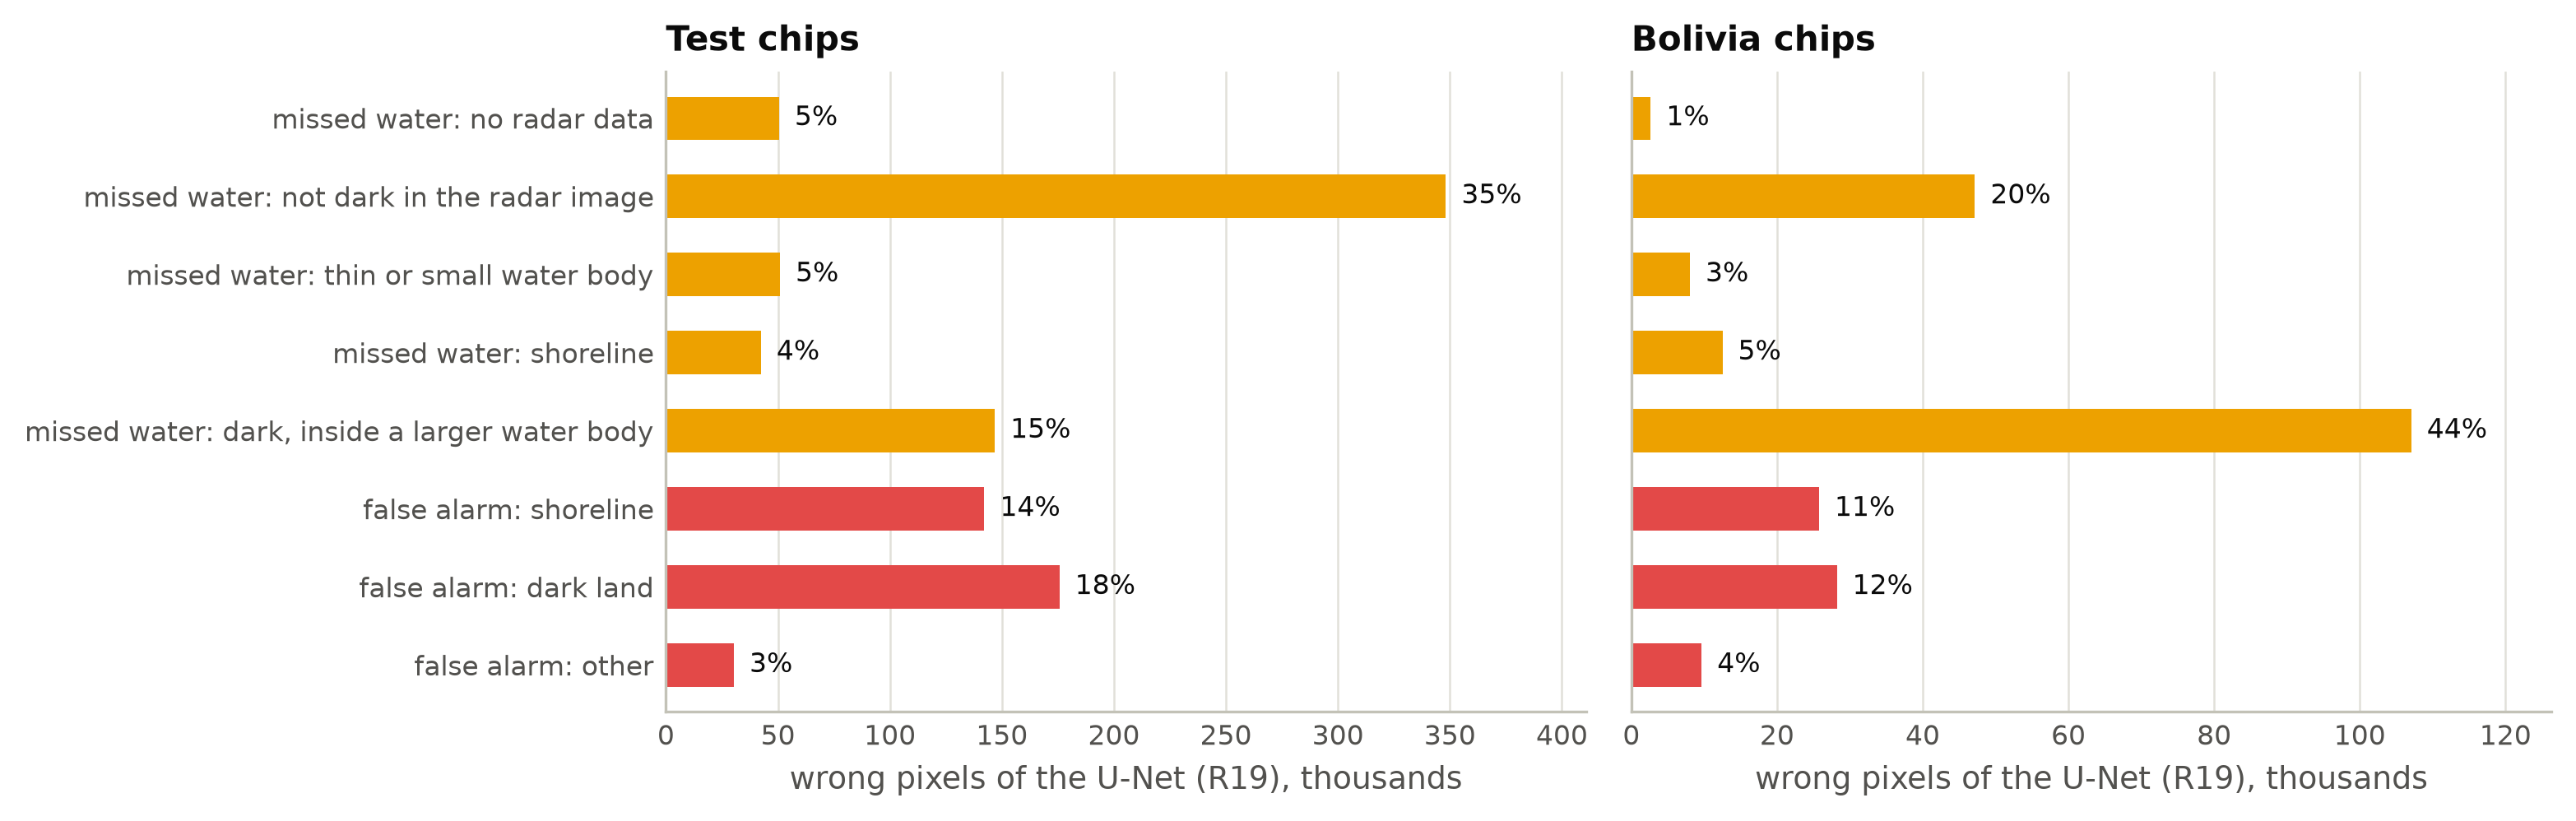

In [5]:
display(Image(filename=str(make_figures.fig_error_budget()), width=900))
plt.close("all")

## 3. The chips with the lowest IoU

In [6]:
unet, otsu = tables[RUN], tables["R00"].set_index("chip")
worst = unet[unet["n_water"] > 0].sort_values("iou").head(12).copy()
worst["otsu_iou"] = worst["chip"].map(otsu["iou"])
worst["main error"] = worst.apply(lambda r: ea.GROUP_LABELS[ea.failure_group(r)], axis=1)
worst[["split", "chip", "water_frac", "iou", "otsu_iou", "fn", "fp", "main error"]].set_index("chip")

,split,water_frac,iou,otsu_iou,fn,fp,main error
chip,,,,,,,
Ghana_141271,test,0.006,0.000,0.015,1636,0,little or no water (under 1% of the chip)
India_772630,test,0.009,0.000,0.020,1345,51,little or no water (under 1% of the chip)
Paraguay_34417,test,1.000,0.000,0.000,50026,0,no radar data
Somalia_166342,test,0.000,0.000,0.000,12,21,little or no water (under 1% of the chip)
Somalia_60129,test,0.003,0.000,0.006,677,0,little or no water (under 1% of the chip)
Paraguay_80102,test,0.000,0.000,0.000,22,0,little or no water (under 1% of the chip)
Pakistan_70625,test,0.018,0.000,0.039,4667,88,dark water missed
Bolivia_195474,bolivia,0.006,0.000,0.035,1551,771,little or no water (under 1% of the chip)
Bolivia_233925,bolivia,0.000,0.000,0.000,1,1173,little or no water (under 1% of the chip)


## 4. Failing chips by group

A chip fails when its IoU is below 0.5. Chips with under 1% water form their own group (a handful of wrong pixels decides their score); the others are grouped by the category that holds most of their error pixels.

In [7]:
failures, failing = ea.failure_table(unet, reference=tables["R00"])
failures.to_csv(ROOT / "results" / "failure_groups.csv", index=False)
n_defined = int(unet["iou"].notna().sum())
print(f"{len(failing)} of the {n_defined} chips with a defined IoU fail (IoU < 0.5): "
      f"{int((failing['split'] == 'test').sum())} test, {int((failing['split'] == 'bolivia').sum())} Bolivia")
failures

63 of the 101 chips with a defined IoU fail (IoU < 0.5): 54 test, 9 Bolivia


,Failure group,Test chips,Bolivia chips,Mean IoU,Example chip,Example IoU,"Otsu mean IoU, same chips"
0,little or no water (under 1% of the chip),23,3,0.100,Ghana_97059,0.000,0.022
1,water that is not dark in the radar image,14,2,0.226,Sri-Lanka_450918,0.001,0.196
2,dark land taken for water,7,1,0.318,Sri-Lanka_117737,0.097,0.207
3,dark water missed,4,2,0.157,Pakistan_70625,0.000,0.351
4,edges of water bodies,5,0,0.444,USA_778194,0.346,0.212
5,no radar data,1,1,0.007,Paraguay_34417,0.000,0.015


One example chip per group (the group's lowest IoU): VH, the hand label, Otsu and the U-Net.

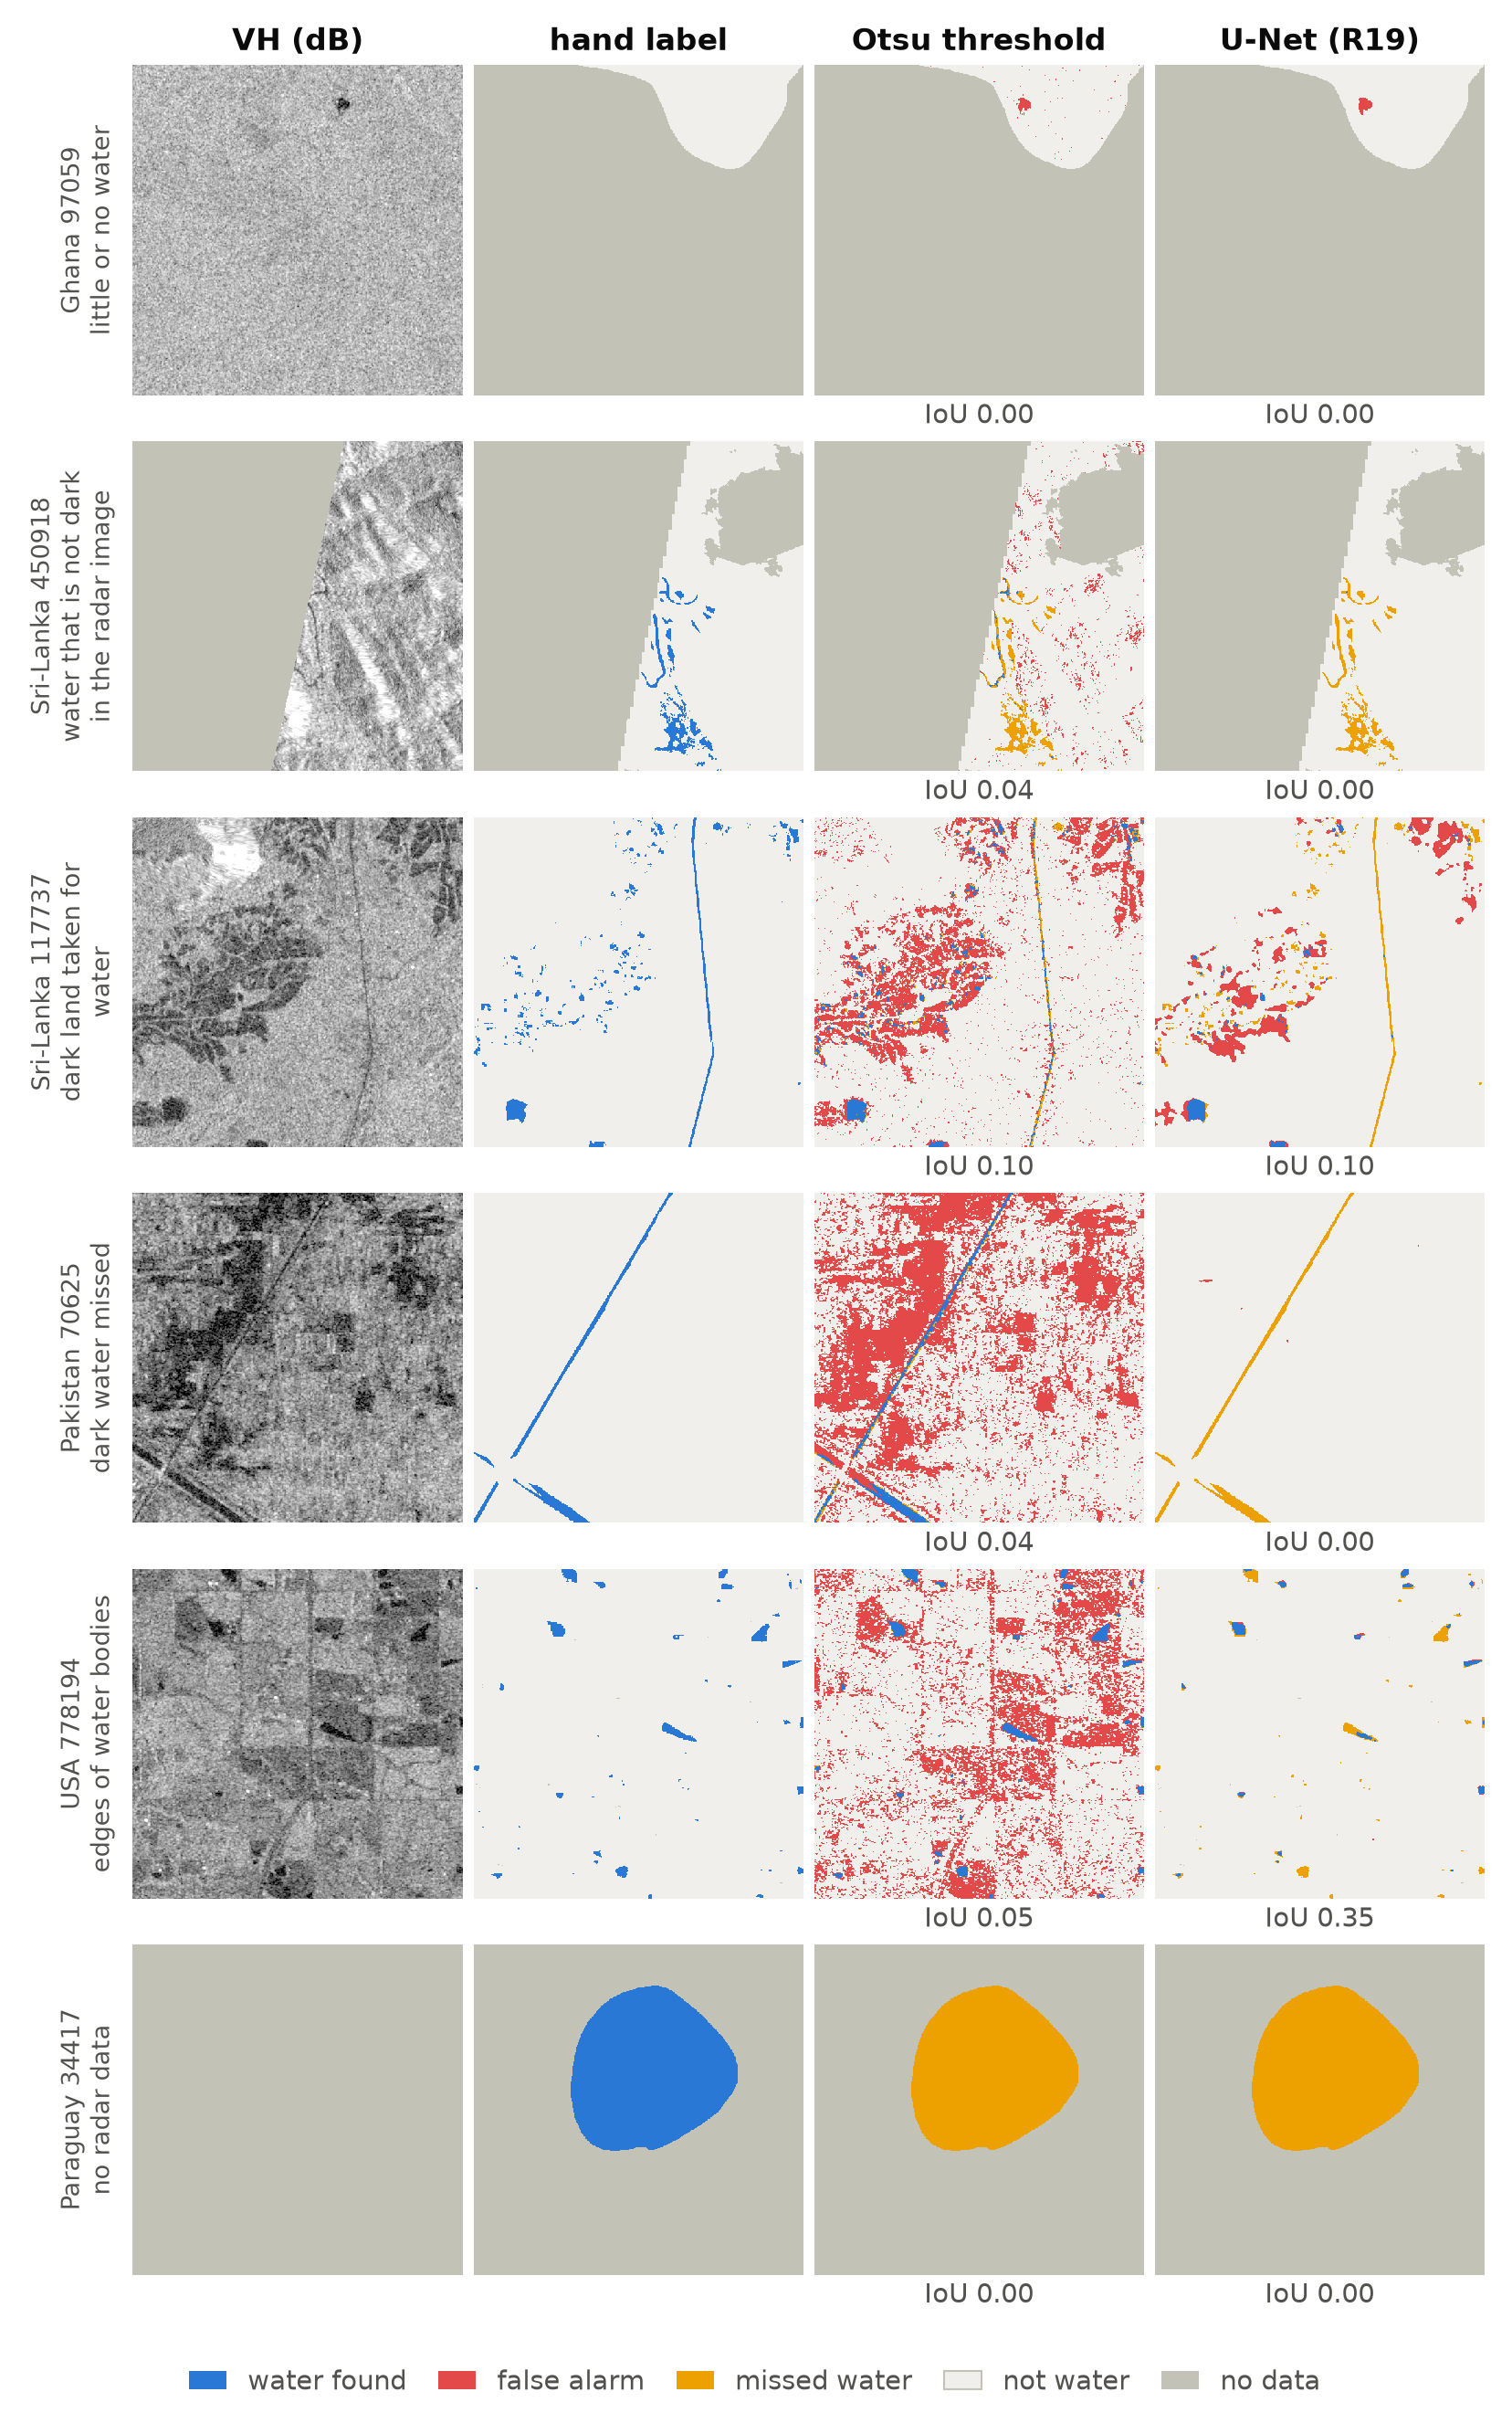

In [8]:
display(Image(filename=str(make_figures.fig_failure_examples()), width=640))
plt.close("all")

## 5. Where the U-Net beats the threshold, and where it does not

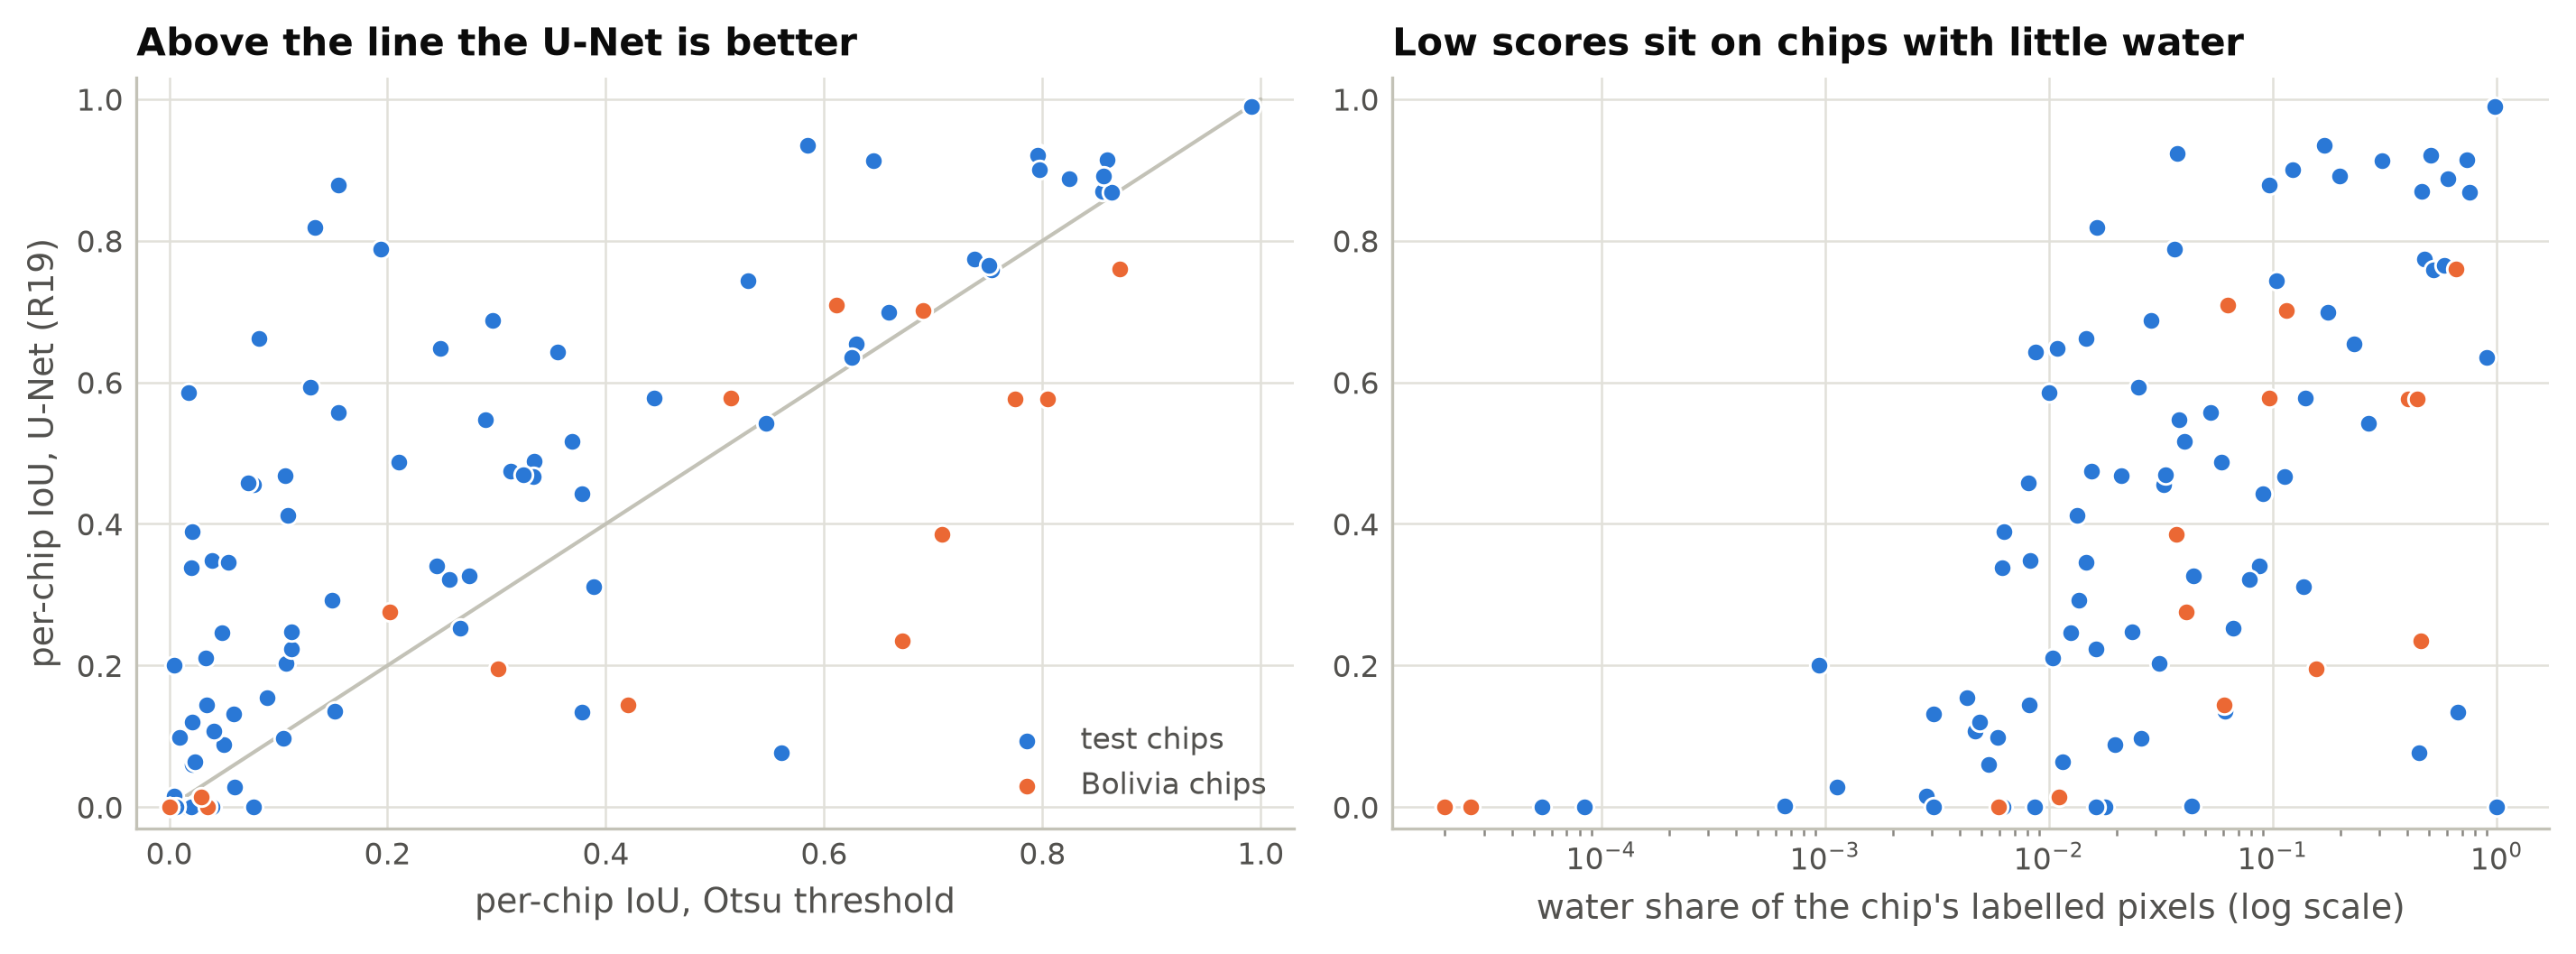

,chips where the U-Net beats Otsu,chips compared
split,,
bolivia,4,15
test,64,86


In [9]:
display(Image(filename=str(make_figures.fig_unet_vs_otsu()), width=860))
plt.close("all")

both = unet[unet["iou"].notna()].copy()
both["otsu_iou"] = both["chip"].map(otsu["iou"])
both = both[both["otsu_iou"].notna()]
wins = both.assign(better=both["iou"] > both["otsu_iou"]).groupby("split")["better"].agg(["sum", "count"])
wins.columns = ["chips where the U-Net beats Otsu", "chips compared"]
wins.to_csv(ROOT / "results" / "unet_vs_otsu_chips.csv")
wins

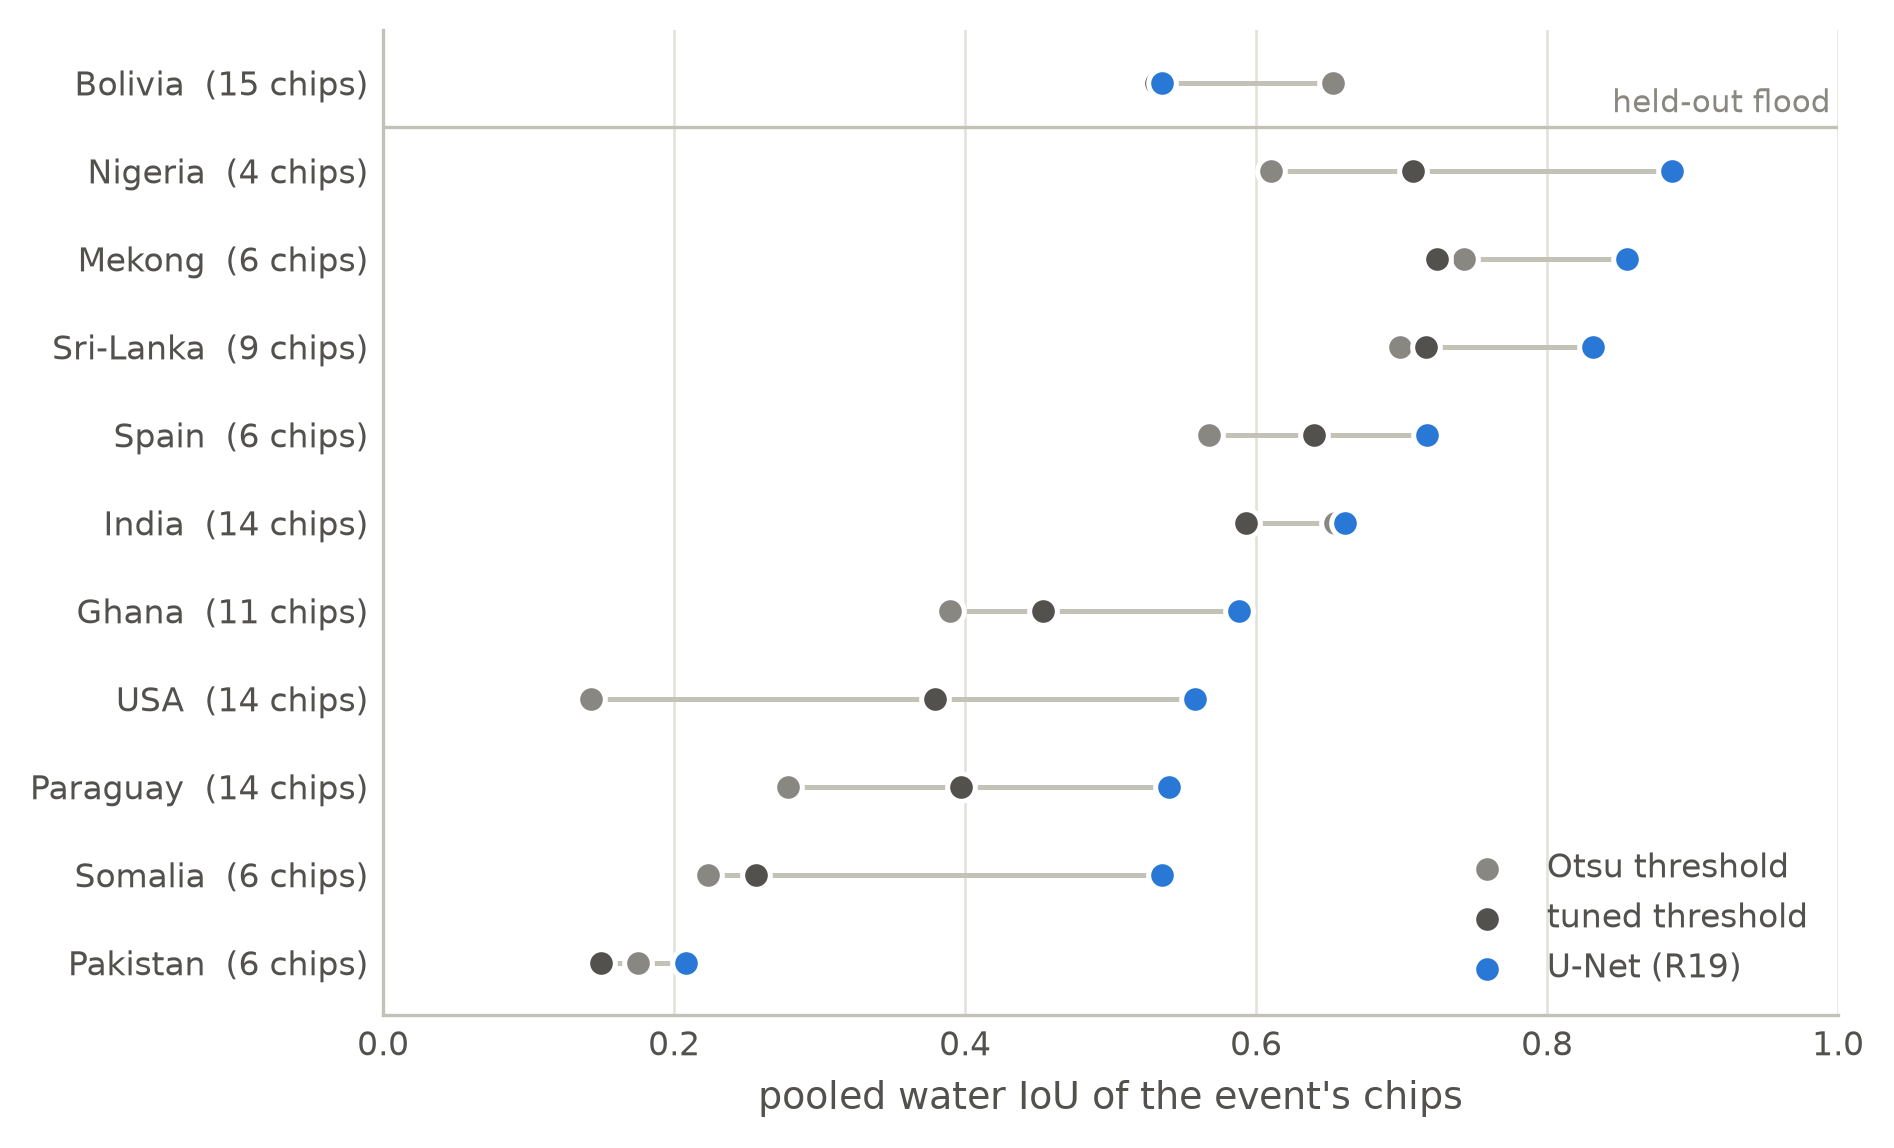

,Otsu,tuned threshold,U-Net R19,chips
event,,,,
Pakistan,0.175,0.150,0.208,6
Bolivia,0.653,0.531,0.535,15
Somalia,0.224,0.256,0.535,6
Paraguay,0.278,0.397,0.540,14
USA,0.143,0.379,0.558,14
Ghana,0.390,0.453,0.588,11
India,0.654,0.593,0.661,14
Spain,0.567,0.640,0.718,6
Sri-Lanka,0.699,0.717,0.831,9


In [10]:
display(Image(filename=str(make_figures.fig_per_event())))
plt.close("all")
events = pd.concat({name: pd.concat([make_figures.event_iou(rid, "test"), make_figures.event_iou(rid, "bolivia")])["iou"]
                    for rid, name in (("R00", "Otsu"), ("R00b", "tuned threshold"), (RUN, f"U-Net {RUN}"))}, axis=1)
events["chips"] = pd.concat([make_figures.event_iou(RUN, "test"), make_figures.event_iou(RUN, "bolivia")])["chips"]
events.to_csv(ROOT / "results" / "per_event_iou.csv")
events.sort_values(f"U-Net {RUN}")

## 6. Bolivia: does the performance hold on an unseen flood? (RQ4)

Pooled scores first, then a look at what makes Bolivia different: how dark its water is in VH compared with the water the model was trained on.

In [11]:
train = load_split("train")
vh_water = {"training": ea.water_vh(train), "test": ea.water_vh(data["test"]), "Bolivia": ea.water_vh(data["bolivia"])}
del train
quant = pd.DataFrame({name: {"water pixels": len(v), "median VH (dB)": np.median(v),
                             f"share darker than the Otsu threshold ({OTSU_DB:.2f} dB)": float((v < OTSU_DB).mean()),
                             f"share darker than the tuned threshold ({TUNED_DB:.2f} dB)": float((v < TUNED_DB).mean())}
                      for name, v in vh_water.items()}).T
quant.to_csv(ROOT / "results" / "water_brightness.csv")
ea.water_vh_histogram(vh_water).to_csv(ROOT / "results" / "water_vh_histogram.csv", index=False)
quant

,water pixels,median VH (dB),share darker than the Otsu threshold (-19.95 dB),share darker than the tuned threshold (-23.60 dB)
training,5446678.000,-25.487,0.790,0.611
test,2515008.000,-25.669,0.826,0.650
Bolivia,451901.000,-24.335,0.865,0.581


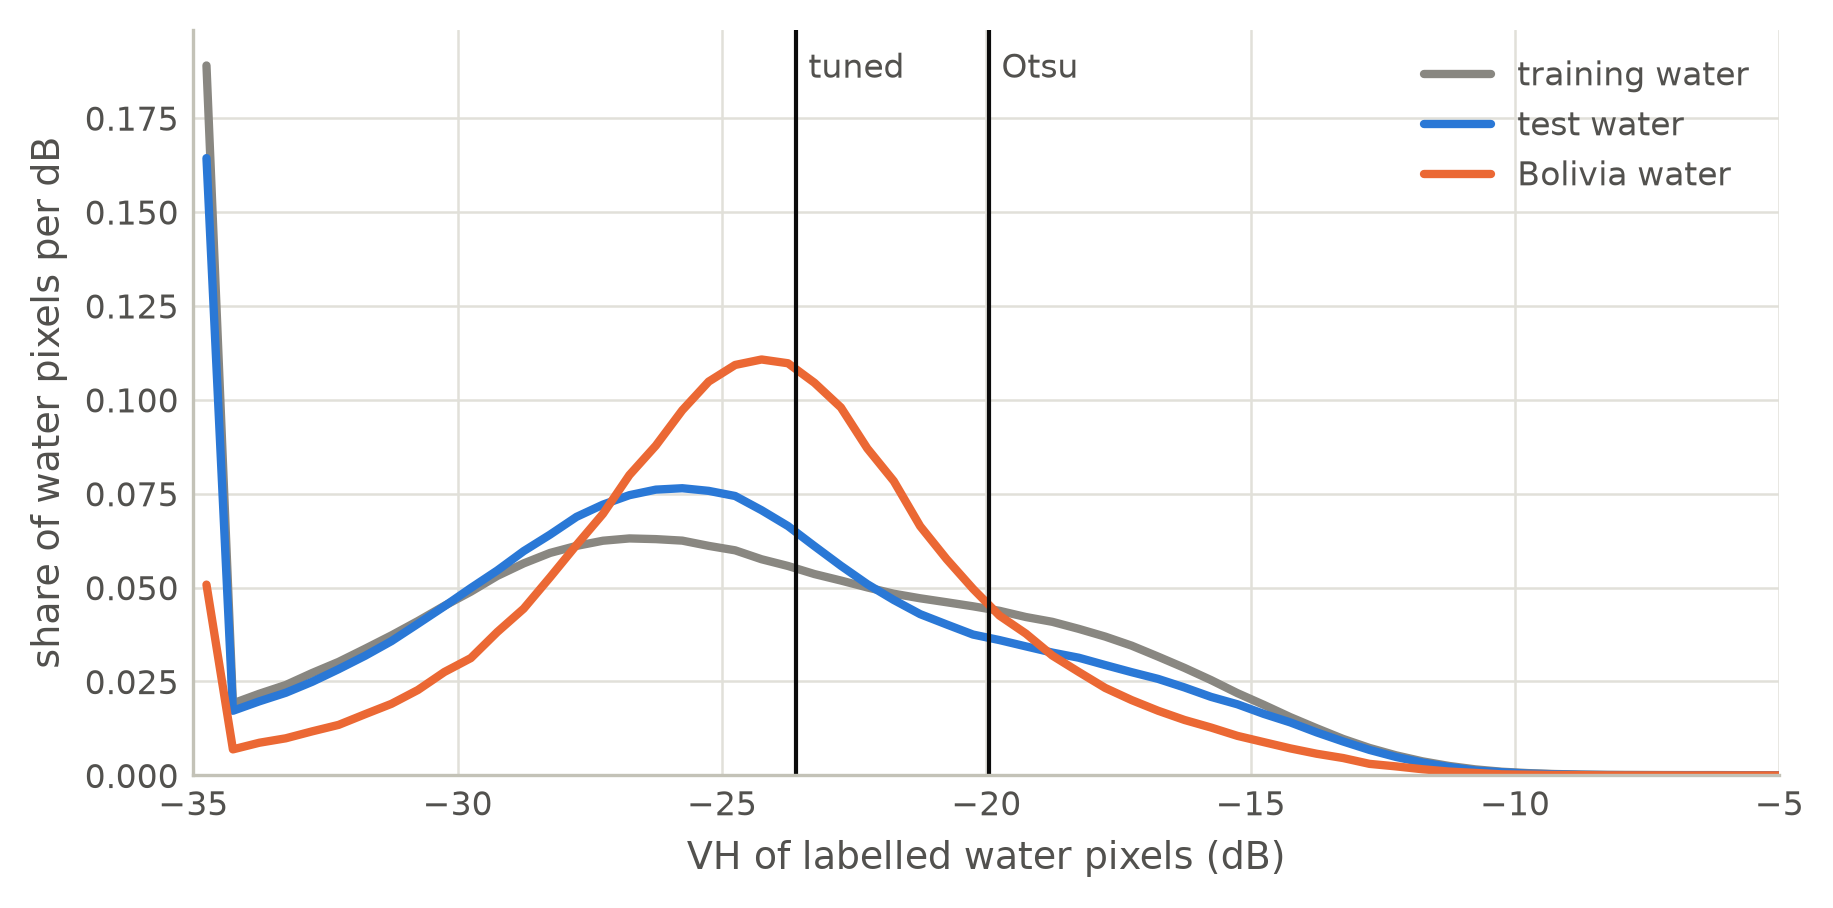

In [12]:
display(Image(filename=str(make_figures.fig_water_brightness()), width=620))
plt.close("all")

In [13]:
bol = unet[unet["split"] == "bolivia"].copy()
bol["otsu_iou"] = bol["chip"].map(otsu["iou"])
bol["main error"] = bol.apply(lambda r: ea.GROUP_LABELS[ea.failure_group(r)] if r["iou"] < 0.5 else "", axis=1)
bol[["chip", "water_frac", "iou", "otsu_iou", "fn", "fp", "miss_not_dark", "miss_no_radar", "main error"]].sort_values("iou").set_index("chip")

,water_frac,iou,otsu_iou,fn,fp,miss_not_dark,miss_no_radar,main error
chip,,,,,,,,
Bolivia_195474,0.006,0.000,0.035,1551,771,1338,0,little or no water (under 1% of the chip)
Bolivia_233925,0.000,0.000,0.000,1,1173,1,0,little or no water (under 1% of the chip)
Bolivia_76104,0.000,0.000,0.000,5,0,5,0,little or no water (under 1% of the chip)
Bolivia_360519,0.011,0.015,0.029,2741,1321,213,2377,no radar data
Bolivia_312675,0.061,0.144,0.420,8153,315,3201,0,water that is not dark in the radar image
Bolivia_242570,0.156,0.195,0.301,19302,13832,3589,0,dark land taken for water
Bolivia_432776,0.460,0.235,0.671,54684,2064,11038,0,dark water missed
Bolivia_379434,0.041,0.276,0.202,6065,6339,5530,0,water that is not dark in the radar image
Bolivia_23014,0.037,0.385,0.708,3962,2138,597,0,dark water missed


## 7. Is the Bolivia problem specific to the model chosen on validation?

The model with the best validation IoU uses ImageNet weights, and notebook 09 showed that the three ImageNet runs are the weakest on Bolivia. The same error breakdown, for the best-validation run of each encoder, shows which kind of error makes the difference.

In [14]:
from src.config import runs_of

all_runs = analysis.runs_table().set_index("Run ID")
picks = {name: all_runs.loc[runs_of(config), "Val IoU (best)"].astype(float).idxmax()
         for name, config in (("Scratch U-Net", "Scratch U-Net"), ("MobileNetV2", "Default"),
                              ("MobileNetV2 + ImageNet", "MobileNetV2 + ImageNet"))}
bolivia = data["bolivia"]
enc_masks = {name: make_figures.predicted_masks(rid, "bolivia") for name, rid in picks.items()}
enc_tables = {name: ea.chip_error_table(m, bolivia, OTSU_DB, "bolivia") for name, m in enc_masks.items()}

by_encoder = pd.DataFrame({f"{name} ({picks[name]})": ea.error_budget(t)["pixels"] for name, t in enc_tables.items()})
by_encoder["Otsu (R00)"] = ea.error_budget(tables["R00"][tables["R00"]["split"] == "bolivia"])["pixels"]
by_encoder = by_encoder.astype(float)
by_encoder.loc["all wrong pixels"] = by_encoder.sum()
by_encoder.loc["pooled IoU on Bolivia"] = [all_runs.loc[rid, "Bolivia IoU"] for rid in picks.values()] + [all_runs.loc["R00", "Bolivia IoU"]]
by_encoder.to_csv(ROOT / "results" / "bolivia_errors_by_encoder.csv")
by_encoder.round(3)

,Scratch U-Net (R16),MobileNetV2 (R02),MobileNetV2 + ImageNet (R19),Otsu (R00)
missed water: no radar data,2382.000,2461.000,2660.000,2963.000
missed water: not dark in the radar image,37594.000,48692.000,47159.000,60985.000
missed water: thin or small water body,5603.000,9974.000,8040.000,0.000
missed water: shoreline,5649.000,13061.000,12503.000,0.000
"missed water: dark, inside a larger water body",19504.000,74706.000,107064.000,0.000
false alarm: shoreline,30888.000,18103.000,25769.000,34181.000
false alarm: dark land,33097.000,12601.000,28213.000,109677.000
false alarm: other,9977.000,6921.000,9649.000,0.000
all wrong pixels,144694.000,186519.000,241057.000,207806.000
pooled IoU on Bolivia,0.726,0.621,0.535,0.653


In [15]:
water = bolivia.labels == WATER
vh = bolivia.images[:, 1]
rows = {}
for name, m in enc_masks.items():
    found, missed = vh[water & m], vh[water & ~m]
    found, missed = found[np.isfinite(found)], missed[np.isfinite(missed)]
    rows[f"{name} ({picks[name]})"] = {
        "recall on Bolivia": float((water & m).sum() / water.sum()),
        "median VH of the water it found (dB)": float(np.median(found)),
        "median VH of the water it missed (dB)": float(np.median(missed)),
        "missed water that is darker than the Otsu threshold": float((missed < OTSU_DB).mean()),
        "missed water that is darker than the tuned threshold": float((missed < TUNED_DB).mean()),
    }
missed_water = pd.DataFrame(rows).T
missed_water.to_csv(ROOT / "results" / "bolivia_missed_water.csv")
missed_water

,recall on Bolivia,median VH of the water it found (dB),median VH of the water it missed (dB),missed water that is darker than the Otsu threshold,missed water that is darker than the tuned threshold
Scratch U-Net (R16),0.844,-24.917,-19.490,0.450,0.137
MobileNetV2 (R02),0.673,-25.346,-21.618,0.667,0.295
MobileNetV2 + ImageNet (R19),0.610,-25.335,-22.394,0.730,0.373


In [16]:
per_chip = pd.DataFrame({f"{name} ({picks[name]})": t.set_index("chip")["iou"] for name, t in enc_tables.items()})
per_chip["Otsu (R00)"] = otsu["iou"].reindex(per_chip.index)
per_chip.insert(0, "water share", enc_tables["MobileNetV2"].set_index("chip")["water_frac"])
per_chip.sort_values("water share", ascending=False)

,water share,Scratch U-Net (R16),MobileNetV2 (R02),MobileNetV2 + ImageNet (R19),Otsu (R00)
chip,,,,,
Bolivia_129334,0.659,0.893,0.844,0.761,0.871
Bolivia_432776,0.460,0.795,0.578,0.235,0.671
Bolivia_314919,0.443,0.776,0.509,0.577,0.775
Bolivia_103757,0.401,0.839,0.830,0.577,0.805
Bolivia_242570,0.156,0.289,0.097,0.195,0.301
Bolivia_294583,0.115,0.750,0.764,0.701,0.691
Bolivia_290290,0.096,0.575,0.460,0.578,0.515
Bolivia_60373,0.063,0.729,0.684,0.709,0.611
Bolivia_312675,0.061,0.278,0.045,0.144,0.420


## 8. Reading (RQ4 and the failure cases)

**Where the best-validation model (R19) fails on the test chips.**

* **Two thirds of its wrong pixels are missed water (65%), one third false alarms.** The largest single category, 35% of all errors, is labelled water that is *not dark* in the radar image, and another 5% lies where the chip has no radar value. No radar-only model can find those pixels, so about 40% of the error on this benchmark is out of the model's reach.
* **The network fixes the main weakness of the threshold.** Otsu makes 2.7 million wrong test pixels, 76% of them dark land taken for water. The U-Net makes 0.99 million, of which 18% are dark land.
* **Thin rivers and shorelines are the smaller part.** Thin or small water bodies account for 5% of the errors, shorelines (missed and false together) for 19%.
* **Most failing chips hold almost no water.** 63 of the 101 chips with a defined IoU score below 0.5. In 26 of them under 1% of the chip is water, so a few hundred pixels decide the score. Then come water that is not dark (16 chips), dark land taken for water (8), dark water missed (6), shorelines (5) and no radar data (2). No chip fails mainly because of thin rivers.
* **Chip by chip the U-Net beats Otsu on 64 of the 86 test chips**, and event by event in all ten training floods (in India only just: 0.661 against 0.654).

**Bolivia (RQ4): the performance does not hold.**

* R19 falls from 0.661 on the test chips to 0.535 on Bolivia, below the Otsu threshold (0.653), and beats Otsu on only 4 of the 15 chips.
* **The dominant error changes.** 44% of its wrong Bolivia pixels are *dark* water inside larger water bodies that it did not mark (15% on the test chips). The threshold finds that water, so this is a failure to transfer, not a limit of the sensor.
* **Bolivia's water is a little brighter than the water the models were trained on** (median VH −24.3 dB against −25.5 dB). Only 58% of it lies below the tuned threshold, but 87% below the Otsu threshold: much of it sits in the range in which, in the training floods, a dark pixel was often land.
* **How much is lost depends on the encoder.** For the best-validation run of each encoder, the dark interior water missed on Bolivia is 20 thousand pixels for the scratch U-Net (R16), 75 thousand for MobileNetV2 (R02) and 107 thousand with ImageNet weights (R19); their recall is 0.84, 0.67 and 0.61. These are single runs; the three-seed means in notebook 09 point the same way.

**Files for the report:** `results/error_budget.csv`, `failure_groups.csv`, `unet_vs_otsu_chips.csv`, `per_event_iou.csv`, `water_brightness.csv`, `water_vh_histogram.csv`, `bolivia_errors_by_encoder.csv` and `bolivia_missed_water.csv`. The figures are drawn from them by `src/make_figures.py`.